## Theoretical and Statistical Applications

Theoretically, this research is gonna allow me to explore how audiences interact with different types of creative content on social media. Graphic design and photography are both in the creative field, but they may attract different audiences and levels of engagement in different ways. 

Statistically, this research is gonna allow me to compare the average number of likes, replies, and reposts for posts that are returned by searches for graphic design and photography. These descriptive statistics will help me to be able to identify the similarities and differences between the two groups with using Bluesky. 

## Variables

Topic - graphic design & photography (this is the independent grouping variable)

Likes, replies, and reposts - the number that is received by a post

Author handle - the account that has published a post

Post text - the text that is used to examine whether a result is relevant to the topic

Post date - the date the post was published, which can help a user identify the differences that are related to the timing of the post

The dependent variables are likes, replies, and reposts. These variables represent different forms of engagement that the user is trying to explore. 

## API endpoints and data quality

1. app.bsky.feed.searchPosts - The endpoint searches public Bluesky posts using a text query, such as "graphic design" or "photography." I used the post text, author handle, publication date, likes, replies, and reposts to compare engagement between the two topics.
2. app.bsk.feed.getPostThread - The endpoint retrieves profile information for the authors found in the post searches. I collected follower counts, following counts, and total profile post counts. I then merged this information with the post dataset using the author handle as the shared key.

### Reliability and limitations
1. Counts can change as people like, repost, or reply
2. Search results are not a random sample of every post about either topic
3. A post mentioning "graphic design" may not actually be about graphic design: a photography search can also return to unrelated results.
4. The same post may appear in both searches as well.
5. getPost Thread may not return every reply, especially when a thread is large or the depth is very limited.
6. Engagement counts do not measure quality, audience size, or whether the engagement is positive.

In [39]:
import requests

url = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"

params = {
    "q": "graphic design",
    "limit": 100
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()  
data = response.json()

In [40]:
response.status_code

200

In [41]:
response.url

'https://api.bsky.app/xrpc/app.bsky.feed.searchPosts?q=graphic+design&limit=100'

In [42]:
response.text[:500]

'{"posts":[{"uri":"at://did:plc:lu7ifqsrvolniaam5btkk4uq/app.bsky.feed.post/3myf3uyfb5s2m","cid":"bafyreiae3vrofgvcrvvlpa75pfs5w675arest6vqe2dyx36e4ho5cn6t3q","author":{"did":"did:plc:lu7ifqsrvolniaam5btkk4uq","handle":"docdiamondfire.bsky.social","displayName":"Doc Diamondfire","avatar":"https://cdn.bsky.app/img/avatar/plain/did:plc:lu7ifqsrvolniaam5btkk4uq/bafkreigdur6lwko6ltqeg2b5ny7t4qyjb476gicidnipu4i2md76obrkbu","associated":{"activitySubscription":{"allowSubscriptions":"followers"}},"label'

In [43]:
data

{'posts': [{'uri': 'at://did:plc:lu7ifqsrvolniaam5btkk4uq/app.bsky.feed.post/3myf3uyfb5s2m',
   'cid': 'bafyreiae3vrofgvcrvvlpa75pfs5w675arest6vqe2dyx36e4ho5cn6t3q',
   'author': {'did': 'did:plc:lu7ifqsrvolniaam5btkk4uq',
    'handle': 'docdiamondfire.bsky.social',
    'displayName': 'Doc Diamondfire',
    'avatar': 'https://cdn.bsky.app/img/avatar/plain/did:plc:lu7ifqsrvolniaam5btkk4uq/bafkreigdur6lwko6ltqeg2b5ny7t4qyjb476gicidnipu4i2md76obrkbu',
    'associated': {'activitySubscription': {'allowSubscriptions': 'followers'}},
    'labels': [],
    'createdAt': '2023-06-07T03:36:20.333Z'},
   'record': {'$type': 'app.bsky.feed.post',
    'createdAt': '2026-10-21T11:58:08.373Z',
    'langs': ['en'],
    'reply': {'parent': {'cid': 'bafyreig36dphyyotxxupp5j6xomqprq4hp5gemsq7zm3fxku4twm4y6554',
      'uri': 'at://did:plc:dx4xunrynxloa7cganyzhhoc/app.bsky.feed.post/3myf3mdqxps24'},
     'root': {'cid': 'bafyreidkyv5ugkzdrva2rkmkz456m2qq627tfog262wi74jzqp24u5xa2y',
      'uri': 'at://did:p

In [44]:
type(data)

dict

In [45]:
data["posts"][0].keys() if data.get("posts") else "No posts returned for this query"

dict_keys(['uri', 'cid', 'author', 'record', 'bookmarkCount', 'replyCount', 'repostCount', 'likeCount', 'quoteCount', 'indexedAt', 'labels'])

In [46]:
posts = data.get("posts") or []
first_handle = posts[0].get("author", {}).get("handle") if posts else None
first_handle

'docdiamondfire.bsky.social'

In [47]:
posts = data.get("posts") or []
first = posts[0] if posts else {}
alt_texts = [
    img.get("alt")
    for img in first.get("record", {}).get("embed", {}).get("images", [])
]
alt_texts

[]

In [48]:
import pandas as pd

df_graphic_design = pd.DataFrame([
    {
        "uri": post.get("uri"),
        "handle": post.get("author", {}).get("handle"),
        "text": post.get("record", {}).get("text"),
        "post_date": post.get("record", {}).get("createdAt") or post.get("indexedAt"),
        "likes": post.get("likeCount", 0),
        "replies": post.get("replyCount", 0),
        "reposts": post.get("repostCount", 0),
        "quotes": post.get("quoteCount", 0),
        "bookmarks": post.get("bookmarkCount", 0),
        "topic": "Graphic Design"
    }
    for post in data.get("posts", [])
])

df_graphic_design.head()

,uri,handle,text,post_date,likes,replies,reposts,quotes,bookmarks,topic
0,at://did:plc:lu7ifqsrvolniaam5btkk4uq/app.bsky...,docdiamondfire.bsky.social,Part of AI psychosis is also definitely people...,2026-10-21T11:58:08.373Z,0,0,0,0,0,Graphic Design
1,at://did:plc:lspmq7oouol2d7cl2nua57in/app.bsky...,kobaneeh.bsky.social,graphic design is my passion,2026-10-21T11:53:49.456Z,0,0,0,0,0,Graphic Design
2,at://did:plc:64tsv6gzrch6uiy3dv2vj5lz/app.bsky...,jcpxdesigns.bsky.social,And the classic,2026-10-21T11:24:14.674Z,1,0,0,0,0,Graphic Design
3,at://did:plc:bxeebhhbs2ctkkty7w54fffx/app.bsky...,forgeandfiction.bsky.social,Showcase your love for iconic martial arts cin...,2026-10-21T11:13:49.082790+00:00,0,0,0,0,0,Graphic Design
4,at://did:plc:r3w3rgxz66r5ei6zdqrf7p7c/app.bsky...,theworldhasended.bsky.social,the world has ended. hedgehogs with authoritar...,2026-10-21T11:09:17.19504500Z,0,0,0,0,0,Graphic Design


In [49]:
photo_url = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"
photo_params = {
    "q": "photography",
    "limit": 100
}
photo_response = requests.get(photo_url, params=photo_params, timeout=30)
photo_response.raise_for_status()  
photo_data = photo_response.json()

In [50]:
photo_data

{'posts': [{'uri': 'at://did:plc:wuqlaapn5mm3q4awwno3pjjg/app.bsky.feed.post/3myf3wfkq222u',
   'cid': 'bafyreib2v56gcac5nnc6v6kf3zzw6ask2oyrczjmyk3745u7fwo2bwnsgi',
   'author': {'did': 'did:plc:wuqlaapn5mm3q4awwno3pjjg',
    'handle': 'd-a-n-n-n-y.bsky.social',
    'displayName': 'D A N',
    'avatar': 'https://cdn.bsky.app/img/avatar/plain/did:plc:wuqlaapn5mm3q4awwno3pjjg/bafkreib6yzwbiurui4ojsbyyo3jgv4cnrraxl5oju5xczpkpk5q4as34yu',
    'associated': {'activitySubscription': {'allowSubscriptions': 'followers'}},
    'labels': [],
    'createdAt': '2025-05-18T20:06:32.341Z'},
   'record': {'$type': 'app.bsky.feed.post',
    'createdAt': '2026-10-21T11:58:55.684Z',
    'embed': {'$type': 'app.bsky.embed.images',
     'images': [{'alt': '',
       'aspectRatio': {'height': 2900, 'width': 2320},
       'image': {'$type': 'blob',
        'ref': {'$link': 'bafkreihvn6fjqvo7naf2usuoco7t754pyaqrmtptw4srh3l3la4iqeylc4'},
        'mimeType': 'image/jpeg',
        'size': 1475878}}]},
    'lan

In [51]:
df_photography = pd.DataFrame([
    {
        "uri": post.get("uri"),
        "handle": post.get("author", {}).get("handle"),
        "text": post.get("record", {}).get("text"),
        "post_date": post.get("record", {}).get("createdAt") or post.get("indexedAt"),
        "likes": post.get("likeCount", 0),
        "replies": post.get("replyCount", 0),
        "reposts": post.get("repostCount", 0),
        "quotes": post.get("quoteCount", 0),
        "bookmarks": post.get("bookmarkCount", 0),
        "topic": "Photography"
    }
    for post in photo_data.get("posts", [])
])

df_photography.head()

,uri,handle,text,post_date,likes,replies,reposts,quotes,bookmarks,topic
0,at://did:plc:wuqlaapn5mm3q4awwno3pjjg/app.bsky...,d-a-n-n-n-y.bsky.social,.\n\nJim Dardanis\n[Western Photography Guild],2026-10-21T11:58:55.684Z,0,0,0,0,0,Photography
1,at://did:plc:mrhbj2yepv6v7tcch5uv6i7c/app.bsky...,adp-landscapephoto.bsky.social,"Coastal Textures \nKettle Cove, Cape Elizabeth...",2026-10-21T11:58:48.212Z,0,0,0,0,0,Photography
2,at://did:plc:acb3v76bzqlk2ht3ivjx35di/app.bsky...,davyhall.bsky.social,City of Columbus Power Station... along Spring...,2026-10-21T11:58:39.314Z,0,0,0,0,0,Photography
3,at://did:plc:dwlkwwki6deqmw3typvdy74w/app.bsky...,pekkabehm.bsky.social,Varpunen. \n\n#valokuvataivas #photography,2026-10-21T11:58:20.353Z,0,0,0,0,0,Photography
4,at://did:plc:wkzvzrcoa7vtn566jw36abcy/app.bsky...,princesskonass.bsky.social,Panini maison à la mortadelle et fromage de ch...,2026-10-21T11:57:39.137Z,1,0,0,0,0,Photography


In [52]:
df_photography.head()

,uri,handle,text,post_date,likes,replies,reposts,quotes,bookmarks,topic
0,at://did:plc:wuqlaapn5mm3q4awwno3pjjg/app.bsky...,d-a-n-n-n-y.bsky.social,.\n\nJim Dardanis\n[Western Photography Guild],2026-10-21T11:58:55.684Z,0,0,0,0,0,Photography
1,at://did:plc:mrhbj2yepv6v7tcch5uv6i7c/app.bsky...,adp-landscapephoto.bsky.social,"Coastal Textures \nKettle Cove, Cape Elizabeth...",2026-10-21T11:58:48.212Z,0,0,0,0,0,Photography
2,at://did:plc:acb3v76bzqlk2ht3ivjx35di/app.bsky...,davyhall.bsky.social,City of Columbus Power Station... along Spring...,2026-10-21T11:58:39.314Z,0,0,0,0,0,Photography
3,at://did:plc:dwlkwwki6deqmw3typvdy74w/app.bsky...,pekkabehm.bsky.social,Varpunen. \n\n#valokuvataivas #photography,2026-10-21T11:58:20.353Z,0,0,0,0,0,Photography
4,at://did:plc:wkzvzrcoa7vtn566jw36abcy/app.bsky...,princesskonass.bsky.social,Panini maison à la mortadelle et fromage de ch...,2026-10-21T11:57:39.137Z,1,0,0,0,0,Photography


## Collect profile data with a second endpoint

The next cell uses `app.bsky.actor.getProfiles`, a different endpoint from `searchPosts`. It requests profiles for the authors found in both topic searches. The author handle is the shared key, so the profile data can be merged into the combined post dataset. Requests are batched to keep each request manageable, and every request is checked before its JSON is processed.

In [53]:
all_handles = list(dict.fromkeys(
    df_graphic_design["handle"].dropna().tolist()
    + df_photography["handle"].dropna().tolist()
))

profile_url = "https://api.bsky.app/xrpc/app.bsky.actor.getProfiles"
profile_rows = []

import time

for i in range(0, len(all_handles), 25):
    batch = all_handles[i:i + 25]

    def fetch(handles):
        r = requests.get(
            profile_url,
            params=[("actors", h) for h in handles],
            timeout=30
        )
        r.raise_for_status()
        return r.json().get("profiles", [])

    try:
        profiles = fetch(batch)
    except requests.RequestException:
        profiles = []
        for handle in batch:
            try:
                profiles.extend(fetch([handle]))
            except requests.RequestException:
                continue

    for profile in profiles:
        profile_rows.append({
            "handle": profile.get("handle"),
            "followers": profile.get("followersCount"),
            "following": profile.get("followsCount"),
            "profile_posts": profile.get("postsCount")
        })

    time.sleep(0.2)

df_profiles = pd.DataFrame(profile_rows)
print("Unique author handles:", len(all_handles))
print("Profiles retrieved:", len(df_profiles))
df_profiles.head()

Unique author handles: 171
Profiles retrieved: 171


,handle,followers,following,profile_posts
0,docdiamondfire.bsky.social,499,431,3782
1,kobaneeh.bsky.social,796,590,29261
2,jcpxdesigns.bsky.social,4218,907,15640
3,forgeandfiction.bsky.social,146,278,241
4,theworldhasended.bsky.social,75,2,50741


## Prepare the engagement comparison

The topic column identifies which search returned each post. I calculated total engagement by adding likes, replies, reposts, quotes, and bookmarks when those metrics were available in the API response. I also compared median engagement because a small number of highly popular posts can increase the average. The results provide a descriptive comparison between graphic design and photography posts, but they do not prove that the topic causes differences in engagement.

In [54]:
df_combined = pd.concat(
    [df_graphic_design, df_photography],
    ignore_index=True
).drop_duplicates(subset="uri").copy()

engagement_cols = ["likes", "replies", "reposts", "quotes", "bookmarks"]
df_combined[engagement_cols] = (
    df_combined[engagement_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

df_combined["total_engagement"] = df_combined[engagement_cols].sum(axis=1)

if "df_profiles" in globals() and not df_profiles.empty:
    df_combined = df_combined.merge(df_profiles, on="handle", how="left")
else:
    for col in ["followers", "following", "profile_posts"]:
        df_combined[col] = pd.NA

print("Combined dataset:", df_combined.shape)
df_combined.head()

Combined dataset: (199, 14)


,uri,handle,text,post_date,likes,replies,reposts,quotes,bookmarks,topic,total_engagement,followers,following,profile_posts
0,at://did:plc:lu7ifqsrvolniaam5btkk4uq/app.bsky...,docdiamondfire.bsky.social,Part of AI psychosis is also definitely people...,2026-10-21T11:58:08.373Z,0,0,0,0,0,Graphic Design,0,499,431,3782
1,at://did:plc:lspmq7oouol2d7cl2nua57in/app.bsky...,kobaneeh.bsky.social,graphic design is my passion,2026-10-21T11:53:49.456Z,0,0,0,0,0,Graphic Design,0,796,590,29261
2,at://did:plc:64tsv6gzrch6uiy3dv2vj5lz/app.bsky...,jcpxdesigns.bsky.social,And the classic,2026-10-21T11:24:14.674Z,1,0,0,0,0,Graphic Design,1,4218,907,15640
3,at://did:plc:bxeebhhbs2ctkkty7w54fffx/app.bsky...,forgeandfiction.bsky.social,Showcase your love for iconic martial arts cin...,2026-10-21T11:13:49.082790+00:00,0,0,0,0,0,Graphic Design,0,146,278,241
4,at://did:plc:r3w3rgxz66r5ei6zdqrf7p7c/app.bsky...,theworldhasended.bsky.social,the world has ended. hedgehogs with authoritar...,2026-10-21T11:09:17.19504500Z,0,0,0,0,0,Graphic Design,0,75,2,50741


In [55]:
summary_df = df_combined.groupby("topic").agg(
    post_count=("uri", "count"),
    average_likes=("likes", "mean"),
    average_replies=("replies", "mean"),
    average_reposts=("reposts", "mean"),
    average_total_engagement=("total_engagement", "mean"),
    median_total_engagement=("total_engagement", "median"),
    p90_total_engagement=(
        "total_engagement",
        lambda s: s.quantile(0.90)
    ),
    average_followers=("followers", "mean")
).round(2)

display(summary_df)

,post_count,average_likes,average_replies,average_reposts,average_total_engagement,median_total_engagement,p90_total_engagement,average_followers
topic,,,,,,,,
Graphic Design,99,4.55,0.48,0.60,6.02,1.0,12.2,2630.76
Photography,100,2.81,0.19,0.28,3.32,2.0,7.1,3048.14


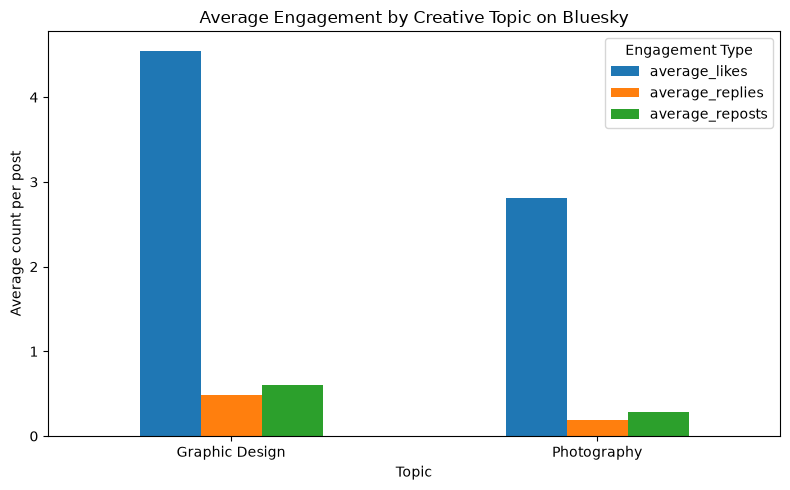

In [56]:
import matplotlib.pyplot as plt

summary_df[["average_likes", "average_replies", "average_reposts"]].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Average Engagement by Creative Topic on Bluesky")
plt.ylabel("Average count per post")
plt.xlabel("Topic")
plt.xticks(rotation=0)
plt.legend(title="Engagement Type")
plt.tight_layout()
plt.show()

In [57]:
if len(summary_df) >= 2:
    averages = summary_df["average_total_engagement"].dropna()

    if len(averages) >= 2:
        higher_topic = averages.idxmax()
        lower_topic = averages.idxmin()

        print(
            f"In this collected sample, {higher_topic} had the higher "
            f"average total engagement ({averages[higher_topic]:.2f}) "
            f"compared with {lower_topic} "
            f"({averages[lower_topic]:.2f})."
        )
        print(
            "This is a descriptive result and may be affected by "
            "search relevance, audience size, post timing, "
            "and overlapping posts."
        )
    else:
        print("Not enough non-missing summary values to compare topics.")
else:
    print("Not enough topic groups were returned to compare.")

In this collected sample, Graphic Design had the higher average total engagement (6.02) compared with Photography (3.32).
This is a descriptive result and may be affected by search relevance, audience size, post timing, and overlapping posts.


# Limitations

There are several limitations to address here:

1. Sample size - The report uses up to 100 search results for each topic. This is a limited sample and may not represent all graphic design and photography posts on Bluesky.
2. Search relevance - Keyword searches may return posts that are not directly related to the topic. Automated or unrelated posts could influence the engagement averages.
3. Overlapping posts - Some posts may appear in both searches. Removing duplicates prevents the same post from being counted twice, but it can also affect which topic a post is assigned to.
4. Audience size and timing - I collected follower counts, but the current comparison does not adjust engagement for differences in audience size. Posts may also have different amounts of time to accumulate engagement.
5. Changing data - Likes, replies, and reposts can change after data collection. The results represent a snapshot of the data available when the API requests were made.

Overall, these limitations show that several factors may affect the results of my report, including the sample size of the posts collected, the relevance of search results based on specific keywords, and the number of overlapping posts between graphic design and photography searches. Differences in audience size and the amount of time posts have been available to receive engagement may also influence the results. Additionally, engagement data can change over time as users like, repost, or reply to posts. These limitations mean that my findings represent only the sample collected through the Bluesky API and may not reflect all graphic design and photography posts on the platform.

# Alternative Approaches 

Another alternative approach is to examine how people interact with graphic design and photography through likes, engagement, and reposts, and how those interactions change over time. My first thought would be to group my data differently and see how both graphic design and photography posts have engaged with and without each other. For my second-to-last thought, it would be to see if my likes for both graphic design and photography posts have differed over time. 

# Next Steps 

In the future, I wanna be able to look at this data about graphic design posts and photography posts in more detail and be able to explore how their engagement compares when the data is combined. I want to be able to see whether combining likes, reposts, and replies gives me a better understanding of how people interact with different creative content altogether. I would also like to compare the total number of engagements between the two topics to see whether graphic design or photography posts receive more interaction. This could help me to understand how people respond to different kinds of creative work. 

# Conclusion

This report allowed me to examine data from graphic design and photography posts on Bluesky. By using the Bluesky API, I was able to collect information about likes, reposts, and replies to compare engagement between the two topics. Based on my results, graphic design posts received higher average engagement than photography posts in my collected sample. Combining likes, reposts, and replies provided a clearer picture of overall engagement because it included different ways users interact with posts. However, the results may be affected by differences in audience size, the posts returned by the API, and changes in engagement over time. In the future, I would like to explore more posts and investigate whether follower counts influence engagement. This would help me better understand which factors may contribute to higher interaction on Bluesky.

# AI Disclosure 


**AI Tool:** ChatGPT

**Prompts Used:**
- "code"

For my likes report, I used ChatGPT to help me with my code when it came to errors and some troubleshooting. I also used ChatGPT to help me understand my code, but it helped me to fix my problems with my API Python code while working with my Instagram data. I also took the time to review the suggested code and use parts of it to help me complete my report that I created. 

Finally, the interpretations and conclusions in this report are my own understanding of my Instagram data.